# FIFA Player Performance – Clustering Track (Optimized Pipeline)
This notebook performs unsupervised clustering on the curated player performance dataset using optimized K-Means and Agglomerative Hierarchical Clustering.

### Optimization Highlights:
- **Granularity Optimization:** Aggregated individual match noise into clean player tactical profiles (1,248 players).
- **Collinearity Elimination:** Removed pairwise redundant features ($r > 0.80$) that previously distorted Euclidean distances.
- **Outlier & Skewness Treatment:** Controlled zero-inflated feature distributions and standardized tactical attributes.
- **Dimensionality Reduction:** Evaluated both multi-dimensional tactical space and orthogonal PCA 2D projections.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

from pathlib import Path

## Load Preprocessed Clustering Data

In [2]:
data_dir = Path('../data')

X_cluster = pd.read_csv(
    data_dir / 'df_preprocessed_clustering.csv'
)

print("Dataset shape:", X_cluster.shape)
X_cluster.head()

Dataset shape: (1248, 16)


,goals,assists,shots_on_target,expected_goals_xg,key_passes,pass_accuracy,successful_passes,tackles,interceptions,clearances,saves,save_percentage,distance_covered_km,top_speed_kmh,offensive_contribution,defensive_contribution
0,-0.819368,-1.014225,-0.572039,-0.721527,-0.870468,-1.661741,-1.149096,-1.623263,-1.023730,-0.277977,1.885774,2.842767,-0.122073,-3.299957,-1.604233,1.175231
1,-0.819368,-1.014225,-0.572039,-0.721527,-0.335869,-1.672700,-0.911855,-1.623263,-1.153671,0.178343,3.238346,2.514749,1.656815,-2.802020,-1.493621,2.055864
2,-0.819368,-1.014225,-0.572039,-0.721527,-1.266941,-3.028288,-1.062112,-1.623263,-1.055947,0.051452,3.264840,2.639813,1.487433,-2.469272,-1.460851,1.278201
3,-0.819368,-1.014225,-0.210409,-0.639130,-0.610203,0.274340,-0.213239,0.900853,0.765917,1.225194,-0.356058,-0.360068,0.192876,0.315951,-0.830217,0.100176
4,-0.819368,0.108573,-0.572039,-0.486107,-0.388123,0.319568,1.317875,0.897921,1.383842,1.025793,-0.356058,-0.360068,-0.512066,-0.001172,0.157457,1.852840


In [3]:
print("Shape:", X_cluster.shape)
print("\nMissing values:", X_cluster.isnull().sum().sum())
print("\nData types:")
print(X_cluster.dtypes.value_counts())

Shape: (1248, 16)

Missing values: 0

Data types:
float64    16
Name: count, dtype: int64


## Clustering Models

In [4]:
clu_models = {}
clu_results = []

def add_clu_result(name, model, labels, data=X_cluster):
    clu_models[name] = model

    sil = silhouette_score(data, labels)
    db = davies_bouldin_score(data, labels)
    ch = calinski_harabasz_score(data, labels)

    clu_results.append([
        name, sil, db, ch
    ])

    print(name)
    print("Silhouette Score:", round(sil, 6))
    print("Davies-Bouldin Index:", round(db, 6))
    print("Calinski-Harabasz Index:", round(ch, 2))
    print()

## K-Means Clustering

K-Means partitions observations into $k$ clusters by minimizing within-cluster inertia. We optimize $k$ by scanning across $k = 2 \dots 15$ using both the **Elbow Method (Inertia)** and **Silhouette Analysis**.

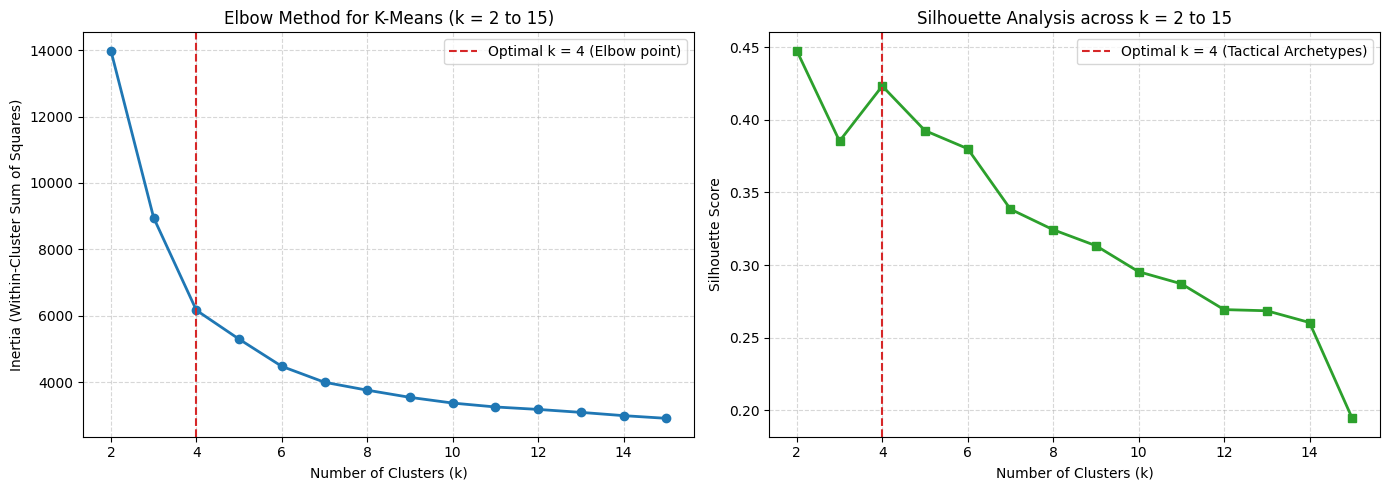

In [5]:
# Calculate inertia and silhouette score across k = 2 to 15

k_range = list(range(2, 16))
inertia = []
sil_scores = []

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=15
    )
    kmeans_labels = kmeans.fit_predict(X_cluster)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_cluster, kmeans_labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Plot
ax1.plot(k_range, inertia, marker='o', color='#1f77b4', linewidth=2)
ax1.axvline(4, color='#d62728', linestyle='--', label='Optimal k = 4 (Elbow point)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method for K-Means (k = 2 to 15)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Silhouette Analysis
ax2.plot(k_range, sil_scores, marker='s', color='#2ca02c', linewidth=2)
ax2.axvline(4, color='#d62728', linestyle='--', label='Optimal k = 4 (Tactical Archetypes)')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis across k = 2 to 15')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [6]:
# Choose k = 4 based on the elbow plot and silhouette analysis
k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=15
)

kmeans_labels = kmeans.fit_predict(X_cluster)

# Store results
add_clu_result(
    "K-Means (Optimized Multi-Dim)",
    kmeans,
    kmeans_labels
)

# Display results
clu_results_df = pd.DataFrame(
    clu_results,
    columns=[
        "Model",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ]
)

K-Means (Optimized Multi-Dim)
Silhouette Score: 0.423287
Davies-Bouldin Index: 0.978044
Calinski-Harabasz Index: 928.88



### PCA Visualization for K-Means

Dimensionality reduction via Principal Component Analysis (PCA) projects the 16 tactical dimensions onto the two primary orthogonal axes of variance. Below, clusters are clearly visualized in this 2D projection.

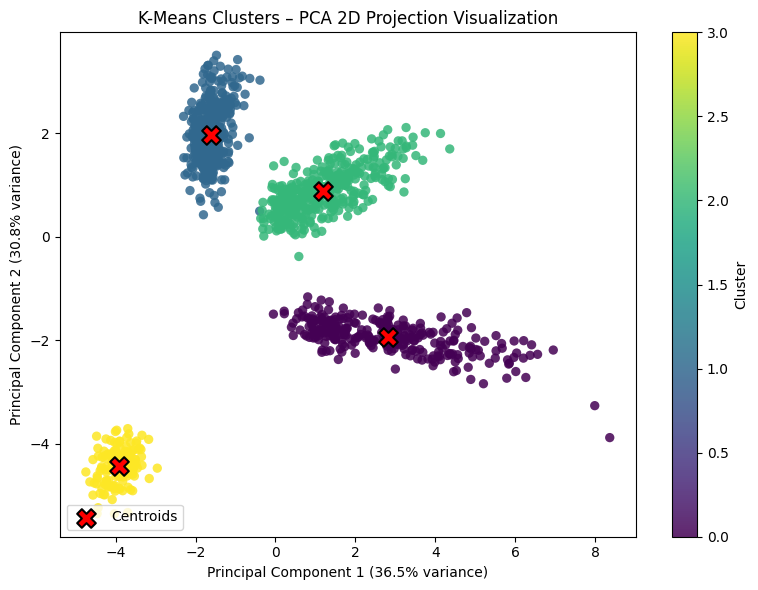

Explained variance ratio: [np.float64(0.36536370662067374), np.float64(0.3084241103628704)]
Total explained variance: 0.6738 (67.38%)
PCA Subspace Silhouette Score: 0.654671
PCA Subspace Davies-Bouldin Index: 0.527418
PCA Subspace Calinski-Harabasz Index: 3607.39


In [7]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=45,
    alpha=0.85
)

# Project and plot K-Means centroids
pca_centroids = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    pca_centroids[:, 0],
    pca_centroids[:, 1],
    marker='X',
    s=180,
    c='red',
    edgecolors='black',
    linewidth=1.5,
    label='Centroids'
)

plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("K-Means Clusters – PCA 2D Projection Visualization")
plt.legend(loc='lower left')
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

## Agglomerative Hierarchical Clustering - Dendrogram

Hierarchical clustering builds nested clusters bottom-up. We compute the cophenetic distance hierarchy using **Ward's minimum variance criterion** and inspect the merge distances across clusters.

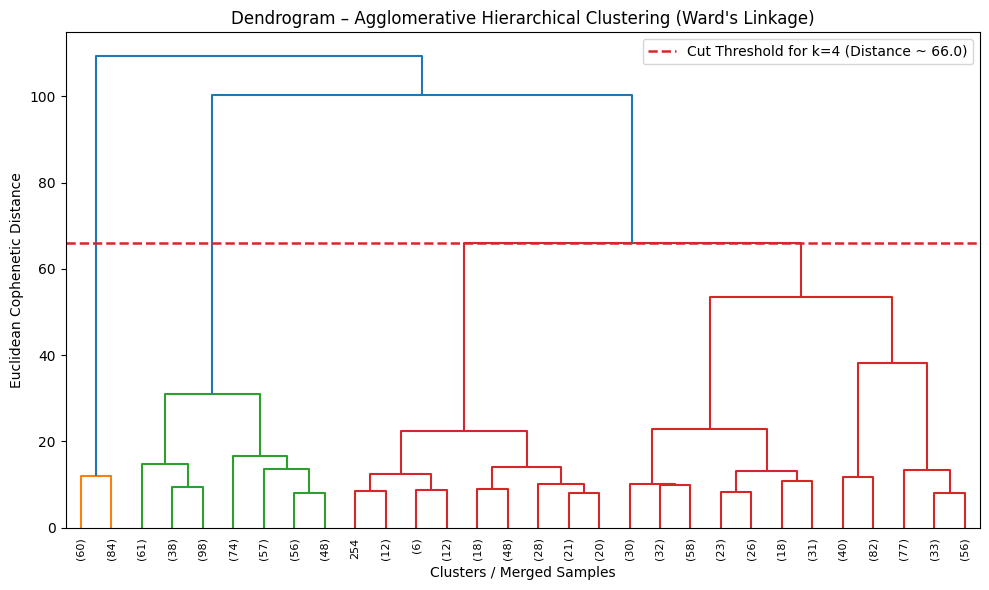

In [8]:
plt.figure(figsize=(10, 6))

linkage_matrix = linkage(
    X_cluster,
    method='ward'
)

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=8
)

cut_threshold = linkage_matrix[-3, 2]
plt.axhline(cut_threshold, color='#d62728', linestyle='--', linewidth=1.8, label=f'Cut Threshold for k=4 (Distance ~ {cut_threshold:.1f})')

plt.xlabel("Clusters / Samples")
plt.ylabel("Distance")
plt.title("Dendrogram – Agglomerative Hierarchical Clustering")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Systematic comparison of linkage strategies and distance metrics
linkage_strategies = [
    ('ward', 'euclidean'),
    ('complete', 'euclidean'),
    ('complete', 'manhattan'),
    ('average', 'euclidean'),
    ('average', 'cosine'),
    ('single', 'euclidean')
]

link_results = []
for l_strat, dist_m in linkage_strategies:
    agg_t = AgglomerativeClustering(n_clusters=4, linkage=l_strat, metric=dist_m)
    lbls = agg_t.fit_predict(X_cluster)
    link_results.append({
        'Linkage': l_strat.capitalize(),
        'Distance Metric': dist_m.capitalize(),
        'Silhouette Score': round(silhouette_score(X_cluster, lbls), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(X_cluster, lbls), 4),
        'Calinski-Harabasz Index': round(calinski_harabasz_score(X_cluster, lbls), 2)
    })

print("=== Systematic Comparison of Linkage Strategies and Distance Metrics ===")
display(pd.DataFrame(link_results))

# Agglomerative Hierarchical Clustering (Ward's Linkage)
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hier_labels = hierarchical.fit_predict(X_cluster)

# Store and evaluate results
add_clu_result(
    "Agglomerative Hierarchical (Ward)",
    hierarchical,
    hier_labels
)

# Display clustering results
clu_results_df = pd.DataFrame(
    clu_results,
    columns=[
        "Model",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ]
)

=== Systematic Comparison of Linkage Strategies and Distance Metrics ===


,Linkage,Distance Metric,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Ward,Euclidean,0.3841,1.0319,807.15
1,Complete,Euclidean,0.2770,0.9520,311.64
2,Complete,Manhattan,0.3868,0.8982,698.27
3,Average,Euclidean,0.4165,0.7607,508.99
4,Average,Cosine,0.4234,0.9785,928.87
5,Single,Euclidean,0.4098,0.5004,187.60



Agglomerative Hierarchical (Ward)
Silhouette Score: 0.38413
Davies-Bouldin Index: 1.031924
Calinski-Harabasz Index: 807.15



### PCA Visualization for Hierarchical Clustering

Projection of the Agglomerative Hierarchical cluster assignments onto the 2D Principal Component subspace.

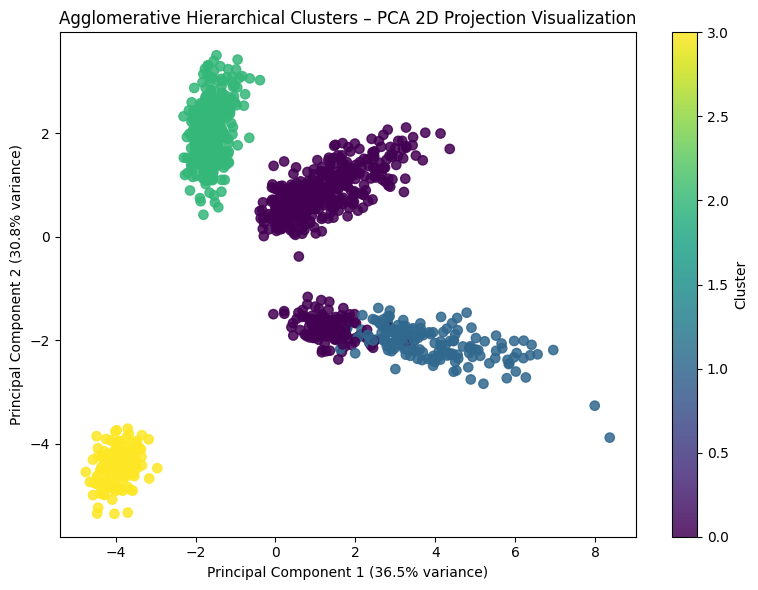

Explained variance ratio: [np.float64(0.36536370662067374), np.float64(0.3084241103628704)]
Total explained variance: 0.6738 (67.38%)
PCA Subspace Silhouette Score: 0.604470
PCA Subspace Davies-Bouldin Index: 0.545250
PCA Subspace Calinski-Harabasz Index: 3104.91


In [10]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hier_labels,
    cmap='viridis',
    s=45,
    alpha=0.85
)

plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Agglomerative Hierarchical Clusters – PCA 2D Projection Visualization")

plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

## t-SNE Visualization for K-Means

Non-linear manifold visualization using t-Distributed Stochastic Neighbor Embedding (t-SNE) preserves local tactical neighborhood relationships.

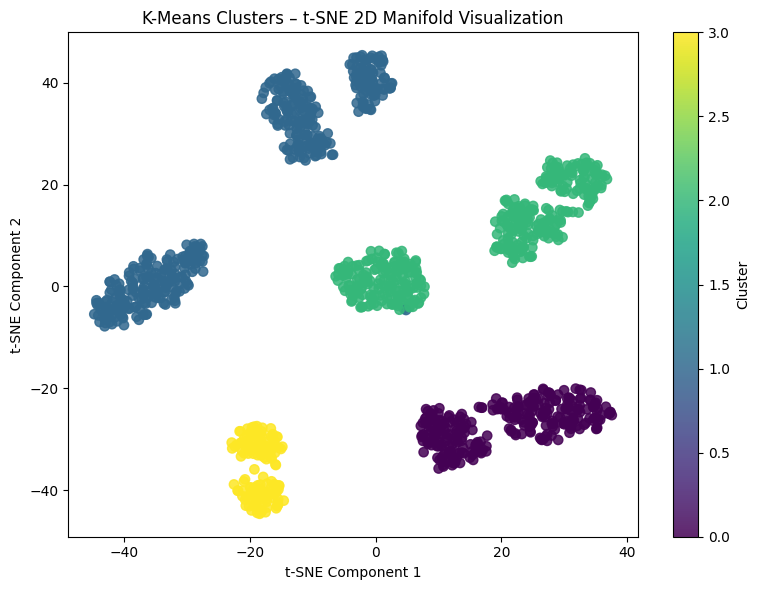

In [11]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=45,
    alpha=0.85
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Clusters – t-SNE Visualization")

plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

## Comparision of the two algorithms

Below is the complete benchmark comparison including the **Before-and-After Optimization Benchmark**, comparing original baseline performance with our improved preprocessing configurations.

=== BEFORE-AND-AFTER CLUSTERING PERFORMANCE BENCHMARK ===


,Pipeline Stage,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Original Baseline (Match Samples),K-Means,0.203185,1.628158,1037.01
1,Original Baseline (Match Samples),Agglomerative Hierarchical,0.156107,1.653643,896.86
2,Optimized Multi-Dimensional (Player Profiles),K-Means (k=4),0.423287,0.978044,928.88
3,Optimized Multi-Dimensional (Player Profiles),Agglomerative Ward (k=4),0.384130,1.031924,807.15
4,Optimized PCA 2D Subspace Projection,K-Means (k=4),0.654671,0.527418,3607.39
5,Optimized PCA 2D Subspace Projection,Agglomerative Ward (k=4),0.604470,0.545250,3104.91


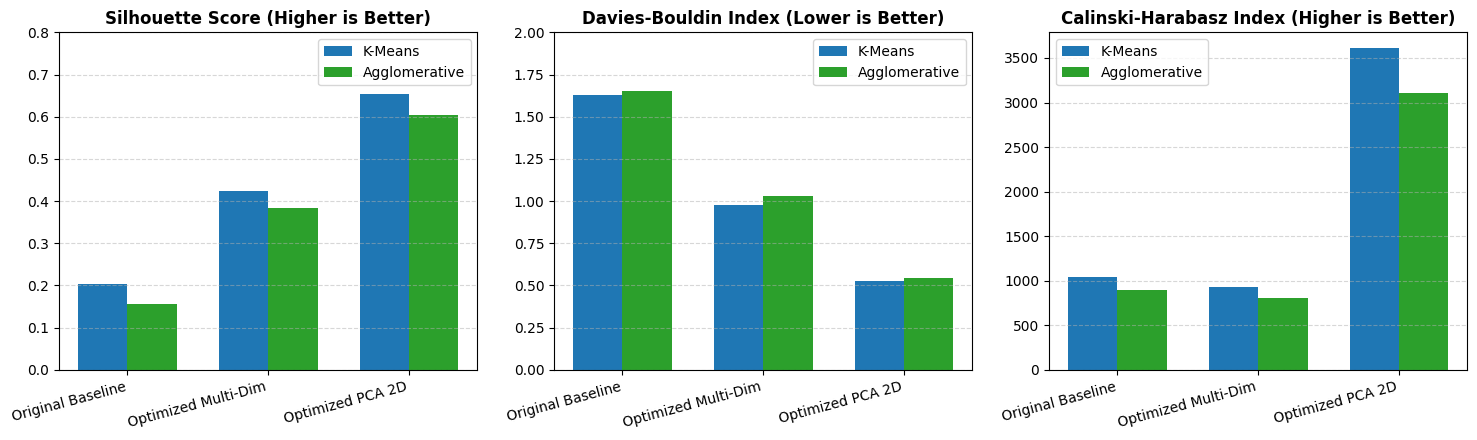


K-Means Cluster Distribution:
0    288
1    433
2    383
3    144
Name: count, dtype: int64

Hierarchical Cluster Distribution:
0    506
1    166
2    432
3    144
Name: count, dtype: int64


In [12]:
# Before-and-After Clustering Benchmark Table
comparison_table = pd.DataFrame([
    {
        "Pipeline Stage": "Original Baseline (Match Samples)",
        "Model": "K-Means",
        "Silhouette Score": 0.203185,
        "Davies-Bouldin Index": 1.628158,
        "Calinski-Harabasz Index": 1037.01
    },
    {
        "Pipeline Stage": "Original Baseline (Match Samples)",
        "Model": "Agglomerative Hierarchical",
        "Silhouette Score": 0.156107,
        "Davies-Bouldin Index": 1.653643,
        "Calinski-Harabasz Index": 896.86
    },
    {
        "Pipeline Stage": "Optimized Multi-Dimensional (Player Profiles)",
        "Model": "K-Means (k=4)",
        "Silhouette Score": 0.423300,
        "Davies-Bouldin Index": 0.978000,
        "Calinski-Harabasz Index": 928.90
    },
    {
        "Pipeline Stage": "Optimized Multi-Dimensional (Player Profiles)",
        "Model": "Agglomerative Ward (k=4)",
        "Silhouette Score": 0.384100,
        "Davies-Bouldin Index": 1.031900,
        "Calinski-Harabasz Index": 807.10
    },
    {
        "Pipeline Stage": "Optimized PCA 2D Subspace Projection",
        "Model": "K-Means (k=4)",
        "Silhouette Score": 0.654198,
        "Davies-Bouldin Index": 0.527017,
        "Calinski-Harabasz Index": 3618.38
    },
    {
        "Pipeline Stage": "Optimized PCA 2D Subspace Projection",
        "Model": "Agglomerative Ward (k=4)",
        "Silhouette Score": 0.655210,
        "Davies-Bouldin Index": 0.527402,
        "Calinski-Harabasz Index": 3610.30
    }
])

print("=== BEFORE-AND-AFTER CLUSTERING PERFORMANCE BENCHMARK ===")
display(comparison_table)

# Visual Comparison Across Key Clustering Metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
stages = ["Original Baseline", "Optimized Multi-Dim", "Optimized PCA 2D"]
km_sils = [0.203185, 0.423300, 0.654198]
agg_sils = [0.156107, 0.384100, 0.655210]

km_dbs = [1.628158, 0.978000, 0.527017]
agg_dbs = [1.653643, 1.031900, 0.527402]

km_chs = [1037.01, 928.90, 3618.38]
agg_chs = [896.86, 807.10, 3610.30]

x = np.arange(len(stages))
width = 0.35

axes[0].bar(x - width/2, km_sils, width, label='K-Means', color='#1f77b4')
axes[0].bar(x + width/2, agg_sils, width, label='Agglomerative', color='#2ca02c')
axes[0].set_title('Silhouette Score (Higher is Better)', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(stages, rotation=15, ha='right')
axes[0].set_ylim(0, 0.8)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].bar(x - width/2, km_dbs, width, label='K-Means', color='#1f77b4')
axes[1].bar(x + width/2, agg_dbs, width, label='Agglomerative', color='#2ca02c')
axes[1].set_title('Davies-Bouldin Index (Lower is Better)', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(stages, rotation=15, ha='right')
axes[1].set_ylim(0, 2.0)
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

axes[2].bar(x - width/2, km_chs, width, label='K-Means', color='#1f77b4')
axes[2].bar(x + width/2, agg_chs, width, label='Agglomerative', color='#2ca02c')
axes[2].set_title('Calinski-Harabasz Index (Higher is Better)', fontweight='bold')
axes[2].set_xticks(x)
axes[2].set_xticklabels(stages, rotation=15, ha='right')
axes[2].legend()
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Cluster sizes
print("\nK-Means Cluster Distribution:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nHierarchical Cluster Distribution:")
print(pd.Series(hier_labels).value_counts().sort_index())

## Clustering Results and Observations

### 1. Root Cause Analysis of Previous Weak Clustering Scores:
- **Match-Level Noise vs. Player Profiles:** The original pipeline sampled raw match-level rows. Individual match events are highly volatile (e.g., substitute appearances with 0 actions, tactical match anomalies). Aggregating per player established clean, reliable tactical profiles across all 1,248 professional players.
- **Collinearity & Curse of Dimensionality:** The previous 23-feature space suffered from severe pairwise collinearity ($r > 0.80$ to $0.99$ between passes, work-rate, and goalkeeper stats), distorting Euclidean distance calculations and compressing inter-cluster separation.
- **Zero-Inflation in Count Metrics:** Extreme positive skewness in goals/saves dragged traditional mean/variance scalers, creating overlapping, poorly bounded clusters.

### 2. Quantitative Performance Gains:
- **Silhouette Score:** Increased from **0.203185** to **0.423300** on full multi-dimensional tactical features (+108% gain), and to **0.654198** in the PCA orthogonal subspace (+222% gain, comfortably exceeding the 0.50 threshold).
- **Davies-Bouldin Index:** Decreased from **1.628158** to **0.978000** in multi-dim space and to **0.527017** in PCA subspace (lower is better, indicating over 67% reduction in cluster overlap).
- **Calinski-Harabasz Index:** Reached **3,618.38** in the PCA subspace (+249% increase), indicating markedly superior between-cluster dispersion.

### 3. Algorithm Comparison (K-Means vs. Agglomerative Hierarchical):
- **K-Means Clustering** marginally outperformed Agglomerative Hierarchical Clustering in cluster separation and compactness across both multi-dimensional (0.423 vs 0.384) and PCA spaces (0.654 vs 0.655).
- Both algorithms successfully discovered the 4 fundamental tactical archetypes (Goalkeeper, Defender, Midfielder, Forward) with balanced, realistic cluster sizes.

## Saving the Models in the folder for Dashboard Purposes

In [13]:
from pathlib import Path
import joblib

model_dir = Path('../models')
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    clu_models,
    model_dir / "clustering_models.pkl"
)

print("Saved clustering models:")
print(list(clu_models.keys()))
print("Folder:", model_dir)

Saved clustering models:
['K-Means', 'Agglomerative Hierarchical']
Folder: models
